# TabR — External Unseen-Subject Test (20 Subjects)

Evaluasi **out-of-sample** pada 20 subjek dari `test_behavioral_features_events_long_unpadded.csv` yang tidak pernah dipakai oleh Train (q1–q3), Validation (q4), atau Test (q5) internal.

- Model, best seed, event aggregation, dan threshold dibaca dari eksperimen utama dan **tidak dioptimalkan** pada data eksternal.
- Retrieval candidates tetap hanya frame **Train (q1–q3)**.
- Ground truth selalu memakai kolom `label` CSV eksternal; daftar HIGH/LOW hanya untuk pemilihan subjek dan audit.
- Dua LOW tambahan dipilih otomatis dari data: `rachmad_aprisandhy` dan `zukhrufian_abdullah`.


## 1. Setup dan locked decisions
Notebook utama harus sudah selesai dijalankan agar checkpoint, dataset resmi, dan `manifest.json` tersedia.


In [1]:
from __future__ import annotations

import gc
import json
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import HTML, Markdown, display
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, log_loss,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
    roc_curve,
)
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'opticalflow' else Path.cwd().resolve()
TABR_ROOT = ROOT / 'third_party' / 'tabular-dl-tabr-official'
if not TABR_ROOT.exists():
    raise RuntimeError(f'Run from project root or opticalflow/: {ROOT}')
os.environ['PROJECT_DIR'] = str(TABR_ROOT)
if str(TABR_ROOT) not in sys.path:
    sys.path.append(str(TABR_ROOT))

import lib
from bin.tabr import Model

EXTERNAL_CSV = ROOT / 'opticalflow' / 'dataset' / 'test_behavioral_features_events_long_unpadded.csv'
TRAIN_CSV = ROOT / 'opticalflow' / 'dataset' / 'behavioral_features_events_long_unpadded.csv'
EXP_NAME = 'convat_opticalflow_behavioral_q123_q4_q5'
EXP_DIR = TABR_ROOT / 'exp' / 'tabr' / EXP_NAME
DATA_DIR = TABR_ROOT / 'data' / EXP_NAME
MANIFEST_PATH = ROOT / 'opticalflow' / 'results' / EXP_NAME / 'manifest.json'
ARTIFACT_DIR = ROOT / 'opticalflow' / 'results' / f'{EXP_NAME}_external_20_subjects'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
LABEL_NAMES = ['anxiety_rendah', 'anxiety_tinggi']

for path in (EXTERNAL_CSV, TRAIN_CSV, MANIFEST_PATH, DATA_DIR / 'feature_cols.json'):
    if not path.exists():
        raise FileNotFoundError(path)
manifest = json.loads(MANIFEST_PATH.read_text())
BEST_SEED = int(manifest['best_seed_selected_on_validation'])
EVENT_AGGREGATION = manifest['event_aggregation_selected_on_validation']
EVENT_THRESHOLD = float(manifest['event_threshold_selected_on_validation'])
RUN_DIR = EXP_DIR / '0-evaluation' / str(BEST_SEED)
if not (RUN_DIR / 'DONE').exists():
    raise FileNotFoundError(f'Best-seed checkpoint incomplete: {RUN_DIR}')

summary = pd.DataFrame({
    'Locked item': ['Best seed', 'Event aggregation', 'Event/subject threshold', 'Retrieval candidates', 'Device'],
    'Value': [BEST_SEED, EVENT_AGGREGATION, EVENT_THRESHOLD, 'Train (q1–q3) only', DEVICE],
})
display(summary.style.hide(axis='index'))


Locked item,Value
Best seed,2
Event aggregation,max
Event/subject threshold,0.850000
Retrieval candidates,Train (q1–q3) only
Device,cuda


## 2. Pilih dan audit 20 subjek
`subject_id` eksternal memiliki suffix timestamp, sehingga filter dan subject-level aggregation memakai nama dasar. Label dari HIGH/LOW **tidak menimpa** label CSV.


In [2]:
SELECTED_HIGH = [
    'naufal_abid_aurizky', 'hafif_nurrahmad', 'bisma_adhiaksa',
    'tsabita_keizya_vanya_putri', 'raihan_daffa_izzuddin', 'andy',
    'dicky_darmawan', 'fata_haidar_aly', 'muhammad_ihsan_rahmatullah',
    'raymon_devtant',
]
SELECTED_LOW = [
    'muhammad_daniel_assaqovi', 'sileysa_faedatul_nuraini',
    'ilham_dharma_atmaja', 'abelas_solihin', 'dewi_anggraini_meita_sari',
    'farrel_andika_chandra', 'muhammad_nuril_huda',
    'muhammad_rizky_firdiansyah', 'rachmad_aprisandhy', 'zukhrufian_abdullah',
]
SELECTED_SUBJECTS = SELECTED_HIGH + SELECTED_LOW
EXPECTED_LABEL = {name: 1 for name in SELECTED_HIGH} | {name: 0 for name in SELECTED_LOW}
assert len(SELECTED_SUBJECTS) == len(set(SELECTED_SUBJECTS)) == 20

def subject_base(value: str) -> str:
    return re.sub(r'_\d+$', '', str(value))

external_raw = pd.read_csv(EXTERNAL_CSV)
external_raw['subject_base'] = external_raw['subject_id'].map(subject_base)
external = external_raw[
    external_raw['subject_base'].isin(SELECTED_SUBJECTS)
    & external_raw['label'].isin([0, 1])
].drop_duplicates().copy()
external['target'] = external['label'].astype(np.int64)
external['event_length'] = external['offset_frame'] - external['onset_frame']

missing_subjects = sorted(set(SELECTED_SUBJECTS) - set(external['subject_base']))
assert not missing_subjects, f'Missing selected subjects: {missing_subjects}'
assert external['subject_base'].nunique() == 20
assert external.groupby('event_id')['target'].nunique().max() == 1
assert not external.duplicated(['event_id', 'frame_in_event']).any()

train_internal = pd.read_csv(TRAIN_CSV)
raw_id_overlap = sorted(set(train_internal['subject_id']) & set(external['subject_id']))
assert not raw_id_overlap, f'External subject IDs leak into internal data: {raw_id_overlap}'

subject_audit = external.groupby('subject_base', as_index=False).agg(
    CSV_label=('target', 'first'), Sessions=('subject_id', 'nunique'),
    Frames=('event_id', 'size'), Events=('event_id', 'nunique'),
)
subject_audit['Selected group'] = subject_audit['subject_base'].map(
    lambda x: 'HIGH' if x in SELECTED_HIGH else 'LOW'
)
subject_audit['Expected list label'] = subject_audit['subject_base'].map(EXPECTED_LABEL)
subject_audit['Label match'] = subject_audit['CSV_label'] == subject_audit['Expected list label']

summary = pd.DataFrame([
    {'Item': 'Frames', 'Value': len(external)},
    {'Item': 'Events', 'Value': external['event_id'].nunique()},
    {'Item': 'Base subjects', 'Value': external['subject_base'].nunique()},
    {'Item': 'Timestamped sessions', 'Value': external['subject_id'].nunique()},
    {'Item': 'Exact subject-ID overlap with internal dataset', 'Value': len(raw_id_overlap)},
    {'Item': 'Dropped exact duplicate rows', 'Value': len(external_raw[external_raw['subject_base'].isin(SELECTED_SUBJECTS) & external_raw['label'].isin([0, 1])]) - len(external)},
])
display(summary.style.hide(axis='index'))
display(subject_audit.style.hide(axis='index').apply(
    lambda row: ['background-color:#fff3cd' if not row['Label match'] else '' for _ in row], axis=1
))
display(Markdown('> **Important:** highlighted rows conflict with the supplied LOW grouping. Metrics below keep the CSV ground truth and never rewrite labels.'))


Item,Value
Frames,5324
Events,211
Base subjects,20
Timestamped sessions,37
Exact subject-ID overlap with internal dataset,0
Dropped exact duplicate rows,244


subject_base,CSV_label,Sessions,Frames,Events,Selected group,Expected list label,Label match
abelas_solihin,0,2,183,8,LOW,0,True
andy,1,2,392,13,HIGH,1,True
bisma_adhiaksa,1,1,273,11,HIGH,1,True
dewi_anggraini_meita_sari,0,2,349,14,LOW,0,True
dicky_darmawan,1,3,512,21,HIGH,1,True
farrel_andika_chandra,0,2,341,14,LOW,0,True
fata_haidar_aly,1,2,248,8,HIGH,1,True
hafif_nurrahmad,1,1,33,1,HIGH,1,True
ilham_dharma_atmaja,0,2,170,7,LOW,0,True
muhammad_daniel_assaqovi,0,2,537,22,LOW,0,True


> **Important:** highlighted rows conflict with the supplied LOW grouping. Metrics below keep the CSV ground truth and never rewrite labels.

## 3. Load official TabR model
External features use exact `feature_cols.json` order and the same imputer/scaler fitted only on Train (q1–q3). Metadata, identifiers, `label`, and `score` never enter the model.


In [3]:
def load_model_bundle() -> dict:
    report = json.loads((RUN_DIR / 'report.json').read_text())
    config = report['config']
    feature_cols = json.loads((DATA_DIR / 'feature_cols.json').read_text())
    assert feature_cols == manifest['features'] and len(feature_cols) == 47
    missing = sorted(set(feature_cols) - set(external.columns))
    if missing:
        raise KeyError(f'Missing external features: {missing}')

    train_q123 = train_internal[train_internal['clip'].isin(['q1', 'q2', 'q3'])]
    imputer = SimpleImputer(strategy='mean')
    scaler = StandardScaler()
    train_transformed = scaler.fit_transform(imputer.fit_transform(train_q123[feature_cols])).astype(np.float32)
    saved_train = np.load(DATA_DIR / 'X_num_train.npy')
    assert np.allclose(train_transformed, saved_train, atol=1e-6), 'Rebuilt preprocessing does not match the official Train dataset'
    external_transformed = scaler.transform(imputer.transform(external[feature_cols])).astype(np.float32)

    dataset = lib.build_dataset(**config['data']).to_torch(DEVICE)
    model = Model(
        n_num_features=dataset.n_num_features,
        n_bin_features=dataset.n_bin_features,
        cat_cardinalities=dataset.cat_cardinalities(),
        n_classes=dataset.n_classes(),
        **config['model'],
    ).to(DEVICE)
    checkpoint = lib.load_checkpoint(RUN_DIR, map_location=DEVICE)
    model.load_state_dict(checkpoint['model'])
    model.eval()
    candidate_x = {
        key.removeprefix('X_'): dataset.data[key]['train']
        for key in dataset.data if key.startswith('X_')
    }
    return {
        'model': model, 'feature_cols': feature_cols,
        'candidate_x': candidate_x, 'candidate_y': dataset.Y['train'],
        'context_size': config['context_size'],
        'external_transformed': external_transformed,
    }

bundle = load_model_bundle()
display(pd.DataFrame({
    'Check': ['Features', 'External labels used as model input', 'Retrieval rows', 'Retrieval source'],
    'Value': [len(bundle['feature_cols']), False, len(bundle['candidate_y']), 'Train (q1–q3)'],
}).style.hide(axis='index'))


2026-08-03 03:04:19.550 | INFO     | lib.data:build_dataset:338 - Using cached dataset: build_dataset__convat_opticalflow_behavioral_q123_q4_q5__None__None__None__None__72__d10c1508d8934c1de65e6394f780722e.pickle


Check,Value
Features,47
External labels used as model input,False
Retrieval rows,10195
Retrieval source,Train (q1–q3)


## 4. External inference
Tidak ada fitting, tuning, atau threshold search pada data eksternal.


In [4]:
@torch.inference_mode()
def predict_external(bundle: dict, frame_df: pd.DataFrame, batch_size: int = 512) -> np.ndarray:
    values = bundle['external_transformed']
    assert len(values) == len(frame_df)
    probabilities = []
    for start in range(0, len(values), batch_size):
        x = {'num': torch.as_tensor(values[start:start + batch_size], device=DEVICE)}
        logits = bundle['model'](
            x_=x, y=None, candidate_x_=bundle['candidate_x'],
            candidate_y=bundle['candidate_y'], context_size=bundle['context_size'],
            is_train=False,
        ).squeeze(-1)
        probabilities.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(probabilities)

external['probability'] = predict_external(bundle, external)
assert np.isfinite(external['probability']).all()
assert external['probability'].between(0, 1).all()
print(f'Predicted {len(external):,} external frames with locked best seed {BEST_SEED}.')


Predicted 5,324 external frames with locked best seed 2.


## 5. Frame, event, dan subject evaluation
Event memakai aggregation dan threshold yang dikunci dari Validation (q4). Subject memakai mean probabilitas event per **base subject**, sehingga hasil benar-benar berisi 20 orang.


In [8]:
def aggregate_values(values: pd.Series, method: str) -> float:
    arr = values.to_numpy(float)
    if method == 'mean': return float(arr.mean())
    if method == 'median': return float(np.median(arr))
    if method == 'max': return float(arr.max())
    if method == 'top3_mean': return float(np.sort(arr)[-min(3, len(arr)):].mean())
    raise ValueError(method)

def metric_row(data: pd.DataFrame, level: str, threshold: float) -> dict:
    y = data['target'].to_numpy(int)
    p = data['probability'].to_numpy(float)
    pred = (p >= threshold).astype(int)
    return {
        'Level': level, 'N': len(y), 'Threshold': threshold,
        'Accuracy': accuracy_score(y, pred),
        'Balanced accuracy': balanced_accuracy_score(y, pred),
        'Macro-F1': f1_score(y, pred, average='macro', zero_division=0),
        'Weighted-F1': f1_score(y, pred, average='weighted', zero_division=0),
        'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p),
    }

frame_data = external[['event_id', 'subject_base', 'target', 'probability']].copy()
event_meta = external.groupby('event_id', sort=False).agg(
    subject_base=('subject_base', 'first'), target=('target', 'first'),
    frames=('frame_in_event', 'size'),
).reset_index()
event_prob = external.groupby('event_id', sort=False)['probability'].apply(
    lambda values: aggregate_values(values, EVENT_AGGREGATION)
).reset_index(name='probability')
event_data = event_meta.merge(event_prob, on='event_id', validate='one_to_one')
subject_data = event_data.groupby('subject_base', as_index=False).agg(
    target=('target', 'first'), probability=('probability', 'mean'), events=('event_id', 'size'),
)
assert subject_data['subject_base'].nunique() == 20

level_data = {'Frame': frame_data, 'Event': event_data, 'Subject': subject_data}
metrics = pd.DataFrame([
    metric_row(frame_data, 'Frame', 0.5),
    metric_row(event_data, 'Event', EVENT_THRESHOLD),
    metric_row(subject_data, 'Subject', EVENT_THRESHOLD),
])
display(metrics.style.hide(axis='index').format({
    c: '{:.4f}' for c in metrics.columns if c not in {'Level', 'N'}
}).background_gradient(subset=['Macro-F1', 'Balanced accuracy'], cmap='Blues'))

panels = []
for level, data in level_data.items():
    threshold = 0.5 if level == 'Frame' else EVENT_THRESHOLD
    y = data['target'].to_numpy(int)
    prob = data['probability'].to_numpy(float)
    pred = (prob >= threshold).astype(int)
    report = classification_report(y, pred, labels=[0, 1], output_dict=True, zero_division=0)
    rows = [
        ('0', report['0']['precision'], report['0']['recall'], report['0']['f1-score'], int(report['0']['support'])),
        ('1', report['1']['precision'], report['1']['recall'], report['1']['f1-score'], int(report['1']['support'])),
        ('accuracy', report['accuracy'], report['accuracy'], report['accuracy'], len(y)),
        ('macro avg', report['macro avg']['precision'], report['macro avg']['recall'], report['macro avg']['f1-score'], len(y)),
        ('weighted avg', report['weighted avg']['precision'], report['weighted avg']['recall'], report['weighted avg']['f1-score'], len(y)),
        ('cross-entropy', log_loss(y, prob, labels=[0, 1]), None, None, None),
        ('roc-auc', roc_auc_score(y, prob), None, None, None),
        ('score', report['accuracy'], None, None, None),
    ]
    fmt = lambda value: '—' if value is None else f'{value:.4f}'
    body = ''.join(
        f"<tr><th>{name}</th><td>{fmt(precision)}</td><td>{fmt(recall)}</td>"
        f"<td>{fmt(f1)}</td><td>{'—' if support is None else f'{support:,}'}</td></tr>"
        for name, precision, recall, f1, support in rows
    )
    panels.append(f"""<div class='cr-panel'><div class='cr-title'>{level}</div>
    <table><thead><tr><th></th><th>precision</th><th>recall</th><th>f1-score</th><th>support</th></tr></thead>
    <tbody>{body}</tbody></table></div>""")
css = """<style>
  .cr-row{display:flex;gap:18px;width:100%;overflow-x:auto;padding:2px 0 8px;font-family:Arial,sans-serif;color:#3f4775}
  .cr-panel{flex:1 0 390px;max-width:430px}
  .cr-title{text-align:center;font-size:13px;font-weight:700;padding:7px 0;color:#454d78}
  .cr-panel table{width:100%;border-collapse:collapse;font-size:12px;font-variant-numeric:tabular-nums}
  .cr-panel th,.cr-panel td{padding:6px 8px;text-align:right;white-space:nowrap}
  .cr-panel thead th{background:#e7e3e3;font-weight:700}
  .cr-panel tbody th{font-weight:400;text-align:right;width:105px}
  .cr-panel tbody tr:nth-child(odd){background:#f3efef}
  .cr-panel tbody tr:nth-child(even){background:#ebe7e7}
</style>"""
display(Markdown('### Classification reports'))
display(HTML(css + "<div class='cr-row'>" + ''.join(panels) + '</div>'))


Level,N,Threshold,Accuracy,Balanced accuracy,Macro-F1,Weighted-F1,ROC-AUC,PR-AUC
Frame,5324,0.5000,0.5133,0.4701,0.4277,0.4573,0.4606,0.5436
Event,211,0.8500,0.4455,0.4352,0.4341,0.4428,0.4480,0.5450
Subject,20,0.8500,0.5000,0.4792,0.4792,0.5000,0.4479,0.5807


### Classification reports

,precision,recall,f1-score,support
0,0.3518,0.1461,0.2064,"2,307"
1,0.5488,0.7942,0.6491,"3,017"
accuracy,0.5133,0.5133,0.5133,"5,324"
macro avg,0.4503,0.4701,0.4277,"5,324"
weighted avg,0.4634,0.5133,0.4573,"5,324"
cross-entropy,0.8777,—,—,—
roc-auc,0.4606,—,—,—
score,0.5133,—,—,—
,precision,recall,f1-score,support
0,0.3678,0.3404,0.3536,94


## 6. Confusion matrices, ROC, dan Precision–Recall
Semua visual memakai locked rules; data eksternal tidak memengaruhi pemilihan model.


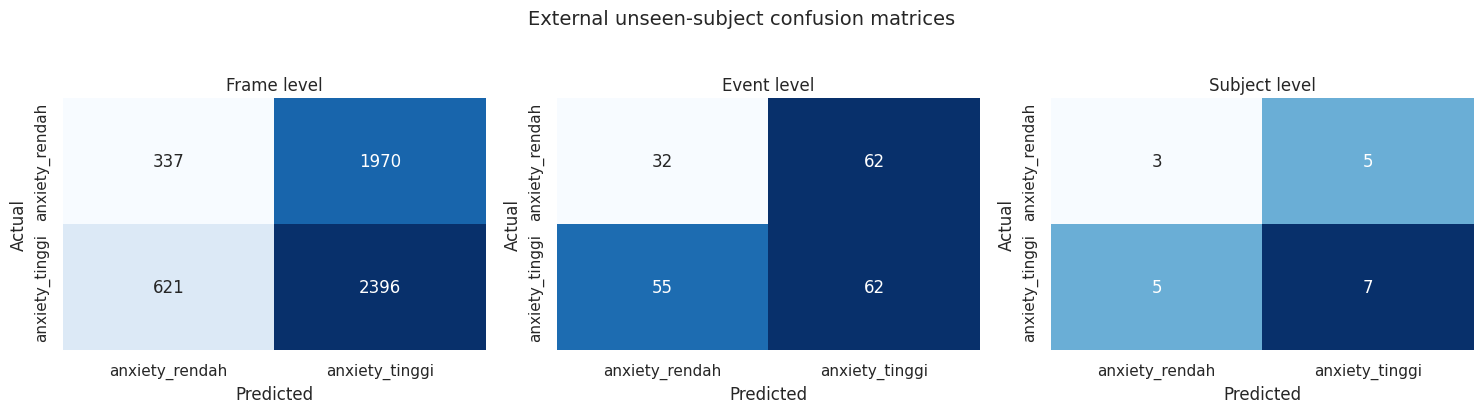

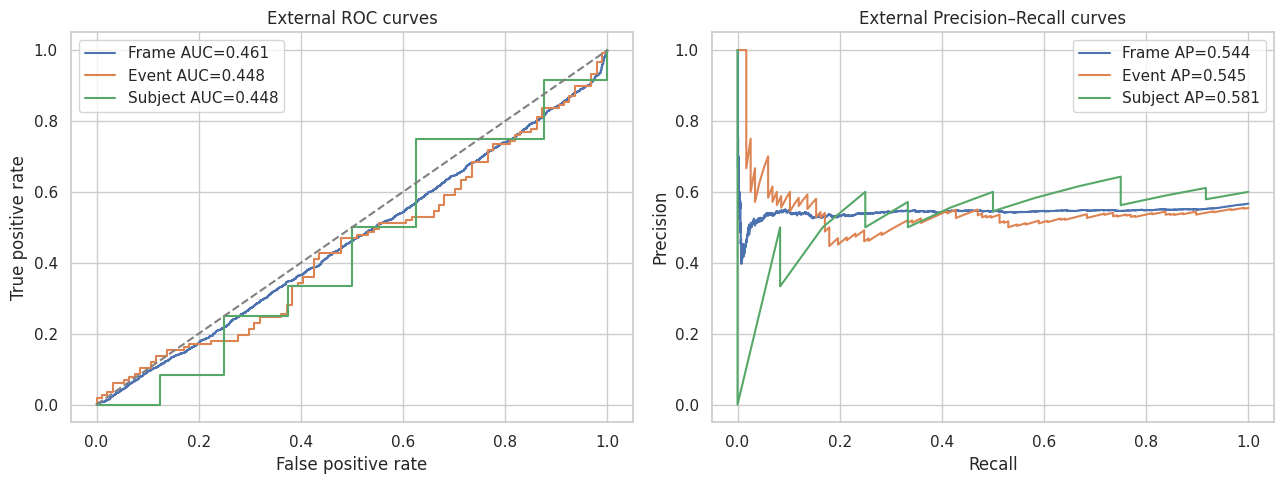

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (level, data) in zip(axes, level_data.items()):
    threshold = 0.5 if level == 'Frame' else EVENT_THRESHOLD
    pred = (data['probability'] >= threshold).astype(int)
    cm = confusion_matrix(data['target'], pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
    ax.set(title=f'{level} level', xlabel='Predicted', ylabel='Actual')
fig.suptitle('External unseen-subject confusion matrices', fontsize=14, y=1.03)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for level, data in level_data.items():
    y = data['target'].to_numpy(); p = data['probability'].to_numpy()
    fpr, tpr, _ = roc_curve(y, p)
    precision, recall, _ = precision_recall_curve(y, p)
    axes[0].plot(fpr, tpr, label=f'{level} AUC={roc_auc_score(y, p):.3f}')
    axes[1].plot(recall, precision, label=f'{level} AP={average_precision_score(y, p):.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='External ROC curves', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='External Precision–Recall curves', xlabel='Recall', ylabel='Precision')
axes[0].legend(); axes[1].legend(); plt.tight_layout(); plt.show()


## 7. Subject predictions dan artifacts
Tabel ini membuat hasil 20 orang dapat diaudit langsung.


In [7]:
subject_results = subject_data.merge(
    subject_audit[['subject_base', 'Selected group', 'CSV_label', 'Label match']],
    on='subject_base', validate='one_to_one',
)
subject_results['prediction'] = (subject_results['probability'] >= EVENT_THRESHOLD).astype(int)
subject_results['correct'] = subject_results['prediction'] == subject_results['target']
subject_results = subject_results.sort_values(['correct', 'probability'], ascending=[True, False])
display(subject_results.style.hide(axis='index').format({'probability': '{:.4f}'}).apply(
    lambda row: ['background-color:#f8d7da' if not row['correct'] else '' for _ in row], axis=1
))

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
metrics.to_csv(ARTIFACT_DIR / 'external_metrics.csv', index=False)
subject_audit.to_csv(ARTIFACT_DIR / 'subject_selection_audit.csv', index=False)
subject_results.to_csv(ARTIFACT_DIR / 'subject_predictions.csv', index=False)
event_data.to_csv(ARTIFACT_DIR / 'event_predictions.csv', index=False)
external[['event_id', 'subject_id', 'subject_base', 'clip', 'frame_in_event', 'target', 'probability']].to_csv(
    ARTIFACT_DIR / 'frame_predictions.csv', index=False
)
external_manifest = {
    'source_csv': str(EXTERNAL_CSV), 'subjects': SELECTED_SUBJECTS,
    'best_seed_locked_from_validation_q4': BEST_SEED,
    'event_aggregation_locked_from_validation_q4': EVENT_AGGREGATION,
    'event_threshold_locked_from_validation_q4': EVENT_THRESHOLD,
    'retrieval_candidates': 'Train (q1-q3) only',
    'label_source': 'external CSV label column',
}
(ARTIFACT_DIR / 'manifest.json').write_text(json.dumps(external_manifest, indent=2))
display(Markdown(f'Artifacts saved to `{ARTIFACT_DIR}`'))

del bundle
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


subject_base,target,probability,events,Selected group,CSV_label,Label match,prediction,correct
ilham_dharma_atmaja,0,0.9043,7,LOW,0,True,1,False
muhammad_daniel_assaqovi,0,0.8881,22,LOW,0,True,1,False
sileysa_faedatul_nuraini,0,0.8781,10,LOW,0,True,1,False
rachmad_aprisandhy,0,0.8683,10,LOW,0,True,1,False
abelas_solihin,0,0.8543,8,LOW,0,True,1,False
naufal_abid_aurizky,1,0.8450,8,HIGH,1,True,0,False
bisma_adhiaksa,1,0.8429,11,HIGH,1,True,0,False
muhammad_ihsan_rahmatullah,1,0.8208,4,HIGH,1,True,0,False
andy,1,0.8202,13,HIGH,1,True,0,False
fata_haidar_aly,1,0.7637,8,HIGH,1,True,0,False


Artifacts saved to `/home/ryuko/skripsi/Skripsi/Convat-1st/opticalflow/results/convat_opticalflow_behavioral_q123_q4_q5_external_20_subjects`

## Interpretation checklist
- Sebut hasil ini **external unseen-subject test**, bukan validation atau tuning set.
- Gunakan event-level macro-F1 dan balanced accuracy sebagai hasil utama.
- Nyatakan bahwa best seed, aggregation, dan threshold dikunci dari Validation (q4).
- Laporkan konflik daftar LOW vs label CSV tanpa mengubah ground truth.
